# Importando

# 1. Importando Bibiotecas

In [1]:
import os
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

# Matplotlib
import matplotlib.ticker as ticker
from matplotlib import rc
from matplotlib.ticker import FormatStrFormatter

# Formato dos números exibidos pelo Pandas
pd.options.display.float_format = '{:.5f}'.format

# mostrando todas as colunas do dataframe
pd.set_option('display.max_columns', None)

# mostrando todas as linhas do dataframe
pd.set_option('display.max_rows', 80)

# Ativa o LaTeX
rc('text', usetex=False)

# Fonte semelhante ao padrão do LaTeX
rc('font', family='serif')

# 2. Dados

In [2]:
# Molécula de Referência
molecula_ref = "SEH"

# Diretorio atual e diretório de dados
dir_base = Path.cwd()
dir_dados = ""

# Definir o caminho dos arquivos de dados
if dir_dados:
    local = dir_base / dir_dados
else:
    local = dir_base

# Verifar se o caminho existe
if not local.exists():
    print(f"Caminho: {local}, não existe!")
    exit(1) 
else:
    print(f"Local de trabalho: \n {local}")

Local de trabalho: 
 c:\Users\laura\Projetos\pylliad\teste_dados


In [3]:
colunas = {"Id1": int, "Label1": str, "Id2": int, "Label2": str, "Dist": float, "Sigma": float, "Frequency": int}

local_arq = local / "traj_w_nj_m_c_rtt_H-dist_CMB_GROUP.dat"
dados = np.loadtxt(local_arq, skiprows=1, dtype=str)                  # Carregar dados
df_seh_cmb = pd.DataFrame(dados, columns=list(colunas.keys()))        # Cria o dataframe
df_seh_cmb = df_seh_cmb.astype(colunas)                               # Ajuste de tipos para cada coluna do dataframe

In [4]:
# Customizando ordem do eixo x (hidrogênios da SEH)
ordem_2D_1H_1H = ["a", "3", "4", "5", "14", "7", "1", "6"]
df_seh_cmb = df_seh_cmb.set_index("Label1").loc[ordem_2D_1H_1H].reset_index()

## 2.1. Análise

In [5]:
dist_min = df_seh_cmb["Dist"].min()
dist_max = df_seh_cmb["Dist"].max()

print(f"Distância mínima.: {dist_min:0.5f}")
print(f"Distância máxima.: {dist_max:0.5f}")

Distância mínima.: 3.61600
Distância máxima.: 4.94400


# 3. Gráfico

## 3.1. SEH- CMB

In [6]:
#
# 00. Definindo o tamanho da figura e o eixo do gráfico
#     - 17,7
#
fig, ax = plt.subplots(1, 1, figsize=(10, 6))

#
# 01. Normalizando os valores do dataframe. Será usado para criar a escala de cores 
#
# norm = plt.Normalize(df_seh_cmb["Dist"].min(), df_seh_cmb["Dist"].max())
norm = plt.Normalize(3.0, 5.0)
cmap = plt.cm.viridis                 # Mapa de cor usado
sizes = df_seh_cmb["Frequency"] / 50  # Tamanho dos círculos do gráfico

#
# 02. Criando o gráfico
#
scatter = ax.scatter(
    x=df_seh_cmb["Label1"],
    y=df_seh_cmb["Label2"],
    s=sizes,                    # Tamanho do Marcador
    c=df_seh_cmb["Dist"],       # Cor do marcador (será mapeadp com cmap)
    cmap=cmap,                  # Colormap
    norm=norm,                  # Valores normalizados
    alpha=0.8
)

#
# 03. Barra de Cores
#
cbar = plt.colorbar(scatter, ax=ax, pad=0.0125)
cbar.set_label("Distance (AA)", fontsize=12)
cbar.minorticks_on()

#
# 04. Bordas do Gráfico
#
for axis in ["bottom", "left", "top", "right"]:
    ax.spines[axis].set_linewidth(2.0)   # espessura da borda
    ax.spines[axis].set_color("0.2")     # cor da borda 
    ax.spines[axis].set_visible(True)

#
# 05. Ticks (Marcadores de valores)
#

# Geral
ax.tick_params(
    which='major',
    length=7.0,       # Comprimento 
    width=1.5,        # Largura
    labelsize=16,     # Tamanho da fonte do texto
    direction='out'
)
ax.tick_params(
    which="minor",
    length=3.5,       # Comprimento 
    width=1.5,        # Largura
    labelsize=14,     # Tamanho da fonte do texto
    direction='out'
)

# Definir a ordem no eixo X 
#plt.xticks(ordem_2D_1H_1H)

# Desativa o marcadores de valores menores
ax.minorticks_off()  

#
# 06. Títulos
#
ax.set_ylabel("CM-betaCD hydrogens atoms",
              fontsize=20,
              weight="bold",
              color="0.2",
              labelpad=15)
ax.set_xlabel("SEL hydrogens atoms",
              fontsize=20,
              weight="bold",
              color="0.2",
              labelpad=15)

# Título/Subtitulo do Gráfico
ax.set_title("SEL - CM-betaCD",
             fontsize=24,
             fontweight="bold",
             pad=25)
ax.text(0.5, 1.02, 
        "Inclusion complex 1:1",
        transform=ax.transAxes,
        ha='center')

#
# 07. Salvado a figura
#
plt.savefig(local / "traj_w_nj_m_c_rtt_H-dist_CMB_GROUP_600dpi",
            bbox_inches="tight",
            dpi=600,
            facecolor=ax.get_facecolor())

#
# 08. Não mostra resultado inline
#
plt.close(fig)

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

#
# 00. Criando tabela pivot (transformação de dados para matriz)
#     - Índice (linhas): Label2 (átomos CMB)
#     - Colunas: Label1 (átomos SEH)
#     - Valores: Dist (distância média entre pares)
#     - Agregação: media (aggfunc="mean")
#
pivot_dist = df_seh_cmb.pivot_table(
    index="Label2",                     # Linhas: grupos CMB
    columns="Label1",                   # Colunas: grupos SEH
    values="Dist",                      # Valores: distâncias
    aggfunc="mean"                      # Função de agregação: média
)

#
# 01. Reordenando colunas conforme ordem customizada
#     - Aplica a ordem predefinida dos hidrogênios da SEH
#
pivot_dist = pivot_dist.reindex(columns=ordem_2D_1H_1H)  # Reordena colunas

#
# 02. Definindo o tamanho da figura e eixo do gráfico
#
fig, ax = plt.subplots(figsize=(10, 7))                  # Cria figura 10x7 polegadas

#
# 03. Criando o heatmap
#     - Exibe a matriz de distâncias com código de cores
#     - Cores: viridis_r (verde/azul invertido)
#     - Anotações: valores formatados com 2 casas decimais
#
sns.heatmap(
    pivot_dist,                         # Dados da matriz
    ax=ax,                              # Eixo do matplotlib
    cmap="viridis_r",                   # Mapa de cores (invertido)
    vmin=3.0,                           # Valor mínimo da escala
    vmax=5.0,                           # Valor máximo da escala
    annot=True,                         # Mostra valores nas células
    fmt=".2f",                          # Formato: 2 casas decimais
    linewidths=0.4,                     # Largura das linhas de grade
    linecolor="0.8",                    # Cor das linhas (cinza claro)
    cbar_kws={"label": "Distância média (Å)", "shrink": 0.85}  # Configurações da barra de cores
)

#
# 04. Configurando rótulos dos eixos
#
ax.set_xlabel("Grupos - SEH", fontsize=14, fontweight="bold", labelpad=12)  # Rótulo X
ax.set_ylabel("Grupos - CMB", fontsize=14, fontweight="bold", labelpad=12)  # Rótulo Y

#
# 05. Configurando título
#
ax.set_title(
    "Heatmap de Distâncias Médias — SEH × CMB",  # Título do gráfico
    fontsize=16, fontweight="bold", pad=18        # Formatação e espaçamento
)

#
# 06. Configurando ticks (marcadores de valores)
#
ax.tick_params(axis="both", labelsize=12)        # Tamanho da fonte dos rótulos
plt.xticks(rotation=0)                           # Sem rotação para eixo X
plt.yticks(rotation=0)                           # Sem rotação para eixo Y

#
# 07. Ajustando layout
#
plt.tight_layout()                               # Remove espaçamento desnecessário

#
# 08. Salvando a figura em arquivo
#
plt.savefig(
    local / "heatmap_dist_SEH_CMB_600dpi",      # Caminho e nome do arquivo
    dpi=600,                                     # Resolução: 600 DPI
    bbox_inches="tight"                          # Remove espaço em branco desnecessário
)

#
# 09. Limpeza e confirmação
#
plt.close(fig)                                   # Fecha a figura para liberar memória
print("Heatmap salvo.")                          # Mensagem de confirmação

Heatmap salvo.


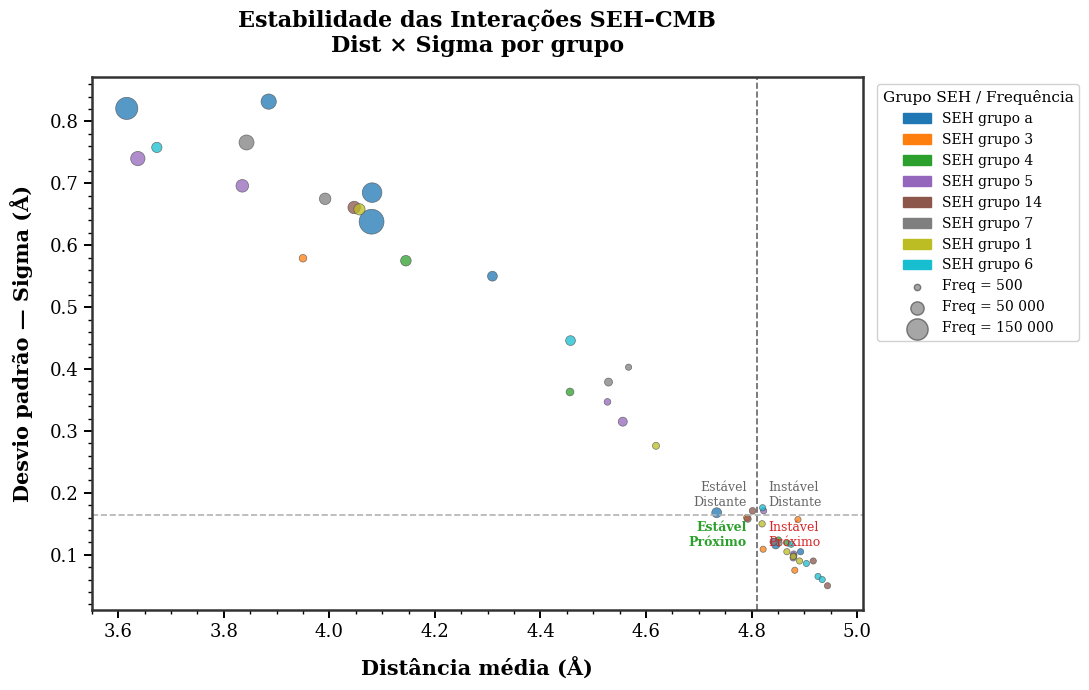

Scatter Dist×Sigma salvo.


In [8]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

#
# 00. Preparando dados para codificação por cores (grupos de átomos SEH)
#     - Extrai todos os grupos únicos de átomos SEH
#     - Cria uma paleta de cores com até 10 cores distintas
#     - Mapeia cada grupo para sua cor correspondente
#
grupos_seh = df_seh_cmb["Label1"].unique()                                           # Lista de grupos únicos
palette = plt.cm.tab10(np.linspace(0, 1, len(grupos_seh)))                          # Paleta de cores
cor_grupo = {g: palette[i] for i, g in enumerate(grupos_seh)}                       # Dicionário cor/grupo
cores = df_seh_cmb["Label1"].map(cor_grupo)                                          # Mapeia cores para cada linha

#
# 01. Normalizando frequências para tamanho dos pontos
#     - Normaliza frequências entre 300 e 320 pixels
#     - Maior frequência = ponto maior
#
freq_norm = (df_seh_cmb["Frequency"] / df_seh_cmb["Frequency"].max()) * 300 + 20    # Normalização e escala

#
# 02. Definindo o tamanho da figura e eixo do gráfico
#
fig, ax = plt.subplots(figsize=(11, 7))                                             # Cria figura 11x7 polegadas

#
# 03. Criando o gráfico scatter (X=Dist, Y=Sigma, Cor=Grupo, Tamanho=Frequência)
#
scatter = ax.scatter(
    x=df_seh_cmb["Dist"],                # Eixo X: distância média
    y=df_seh_cmb["Sigma"],               # Eixo Y: desvio padrão (sigma)
    c=cores,                              # Cores: um color por grupo SEH
    s=freq_norm,                          # Tamanho do marcador: proporcional à frequência
    alpha=0.75,                           # Transparência
    edgecolors="0.3",                     # Cor das bordas dos pontos
    linewidths=0.5                        # Largura das bordas
)

#
# 04. Calculando e traçando linhas de mediana
#     - Mediana de Dist: linha vertical tracejada
#     - Mediana de Sigma: linha horizontal tracejada
#
dist_med  = df_seh_cmb["Dist"].median()                                             # Calcula mediana de Dist
sigma_med = df_seh_cmb["Sigma"].median()                                            # Calcula mediana de Sigma

ax.axvline(dist_med,  color="0.4", ls="--", lw=1.2, label=f"Mediana Dist ({dist_med:.2f} Å)")  # Linha X
ax.axhline(sigma_med, color="0.7", ls="--", lw=1.2, label=f"Mediana Sigma ({sigma_med:.2f} Å)")  # Linha Y

#
# 05. Adicionando anotações para regiões de estabilidade
#     - Quadrantes: Estável/Instável × Distante/Próximo
#
ax.text(dist_med - 0.02, sigma_med + 0.01,  "Estável\nDistante",  ha="right", va="bottom", fontsize=9, color="0.4")
ax.text(dist_med + 0.02, sigma_med + 0.01,  "Instável\nDistante", ha="left",  va="bottom", fontsize=9, color="0.4")
ax.text(dist_med - 0.02, sigma_med - 0.01,  "Estável\nPróximo",   ha="right", va="top",    fontsize=9, color="#2ca02c", fontweight="bold")
ax.text(dist_med + 0.02, sigma_med - 0.01,  "Instável\nPróximo",  ha="left",  va="top",    fontsize=9, color="#d62728")

#
# 06. Criando legenda 1: Grupos de átomos SEH (por cor)
#
patches = [mpatches.Patch(color=cor_grupo[g], label=f"SEH grupo {g}") for g in grupos_seh]  # Cria patches de cor
ax.legend(
    handles=patches,                    # Objetos da legenda
    title="Grupo SEH",                  # Título da legenda
    bbox_to_anchor=(1.01, 1),           # Posição: canto superior direito
    loc="upper left",
    fontsize=10,
    title_fontsize=11,
    framealpha=0.9                      # Transparência da caixa
)

#
# 07. Criando marcadores fictícios para legenda 2: Escala de frequência
#     - Mostra três valores de exemplo (500, 50000, 150000) com seus tamanhos correspondentes
#
for freq_ex, label_ex in zip([500, 50000, 150000], ["500", "50 000", "150 000"]):
    s_ex = (freq_ex / df_seh_cmb["Frequency"].max()) * 300 + 20  # Calcula tamanho do exemplo
    ax.scatter([], [], s=s_ex, c="0.5", alpha=0.7, edgecolors="0.3", label=f"Freq = {label_ex}")

#
# 08. Criando legenda 2: Combinada (Grupos + Frequência)
#
ax.legend(
    handles=patches + ax.get_legend_handles_labels()[0][-3:],  # Combina patches + marcadores de freq
    title="Grupo SEH / Frequência",
    bbox_to_anchor=(1.01, 1),
    loc="upper left",
    fontsize=10,
    title_fontsize=11,
    framealpha=0.9
)

#
# 09. Formatando bordas dos eixos (spines)
#     - Define espessura e cor das linhas de borda
#
for spine in ax.spines.values():
    spine.set_linewidth(1.8)            # Espessura das bordas
    spine.set_color("0.2")              # Cor cinza escuro

#
# 10. Configurando ticks (marcadores de valores) e grid
#
ax.tick_params(which="major", length=6, width=1.4, labelsize=13, direction="out")    # Ticks principais
ax.tick_params(which="minor", length=3, width=1.0, direction="out")                  # Ticks menores
ax.minorticks_on()                      # Ativa ticks menores

#
# 11. Configurando rótulos dos eixos e título
#
ax.set_xlabel("Distância média (Å)", fontsize=15, fontweight="bold", labelpad=12)   # Rótulo eixo X
ax.set_ylabel("Desvio padrão — Sigma (Å)", fontsize=15, fontweight="bold", labelpad=12)  # Rótulo eixo Y
ax.set_title(
    "Estabilidade das Interações SEH–CMB\nDist × Sigma por grupo",  # Título principal + subtítulo
    fontsize=16, fontweight="bold", pad=18
)

#
# 12. Ajustando layout e exibindo
#
plt.tight_layout()                      # Remove espaçamento desnecessário
plt.savefig(
    local / "scatter_dist_sigma_SEH_CMB_600dpi",  # Caminho e nome do arquivo
    dpi=600,                            # Resolução: 600 DPI
    bbox_inches="tight"                 # Remove espaço em branco desnecessário
)

#
# 13. Exibindo e limpeza
#
plt.show()                              # Exibe o gráfico
plt.close(fig)                          # Fecha a figura para liberar memória
print("Scatter Dist×Sigma salvo.")      # Mensagem de confirmação

## 4. Gráfico de barras de frequência por átomo SEH

somamos todas as frequências de um átomo SEH com todos os átomos CMB\
Isso é útil para identificar quais átomos da SEH interagem mais com a CMB ao longo da simulação

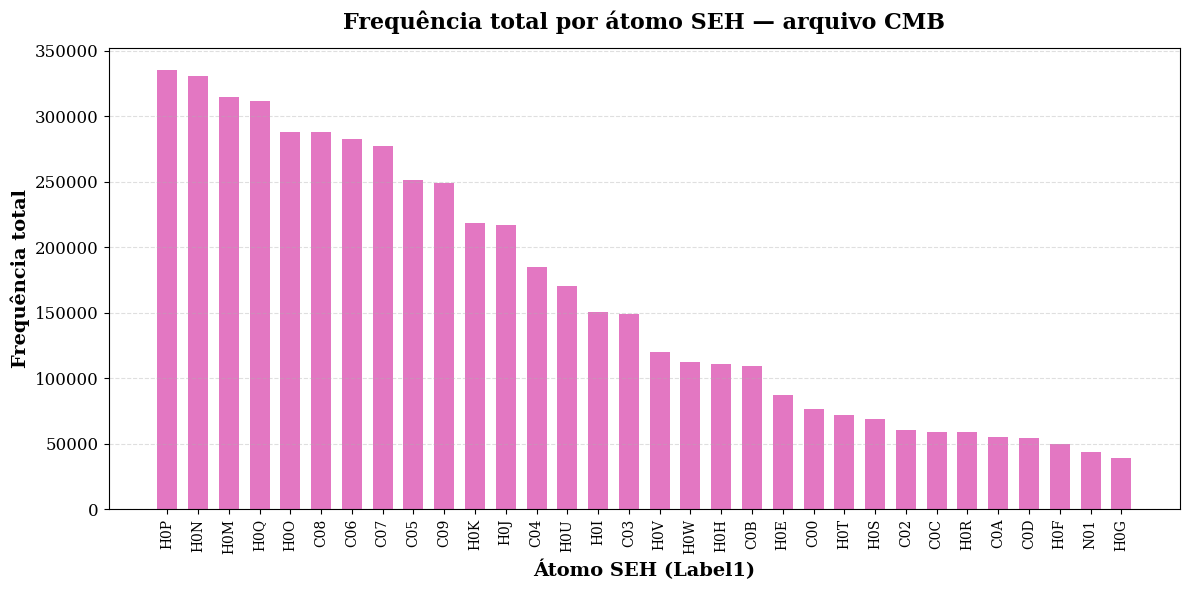

Gráfico de barras salvo em: c:\Users\laura\Projetos\pylliad\teste_dados\bar_freq_total_por_atomo_SEH_600dpi.png


In [9]:
import matplotlib.pyplot as plt

#
# 00. Carregando os dados do arquivo CMB.dat
#
cmb_path = local / "traj_w_nj_m_c_rtt_H-dist_CMB.dat"  # Caminho completo do arquivo
cols = ["Id1", "Label1", "Id2", "Label2", "Dist", "Sigma", "Frequency"]  # Nomes das colunas
df_cmb = pd.read_csv(cmb_path, sep=r"\s+", names=cols, header=0)  # Lê o arquivo com separador whitespace

#
# 01. Agregando frequência total por átomo SEH
#     - Agrupa todos os registros pelo Label1 (átomo SEH)
#     - Soma as frequências dentro de cada grupo
#     - Ordena em ordem decrescente
#
freq_por_seh = df_cmb.groupby("Label1")["Frequency"].sum().sort_values(ascending=False)

#
# 02. Definindo o tamanho da figura e eixo do gráfico
#
fig, ax = plt.subplots(figsize=(12, 6))  # Cria figura e eixo com dimensões 12x6 polegadas

#
# 03. Criando o gráfico de barras
#
ax.bar(
    freq_por_seh.index,        # Eixo X: rótulos dos átomos SEH
    freq_por_seh.values,       # Eixo Y: frequência total de cada átomo
    color="tab:pink",          # Cor das barras
    width=0.65                 # Largura das barras
)

#
# 04. Configurando rótulos dos eixos
#
ax.set_xlabel("Átomo SEH (Label1)", fontsize=14, fontweight="bold")  # Rótulo eixo X
ax.set_ylabel("Frequência total", fontsize=14, fontweight="bold")     # Rótulo eixo Y

#
# 05. Configurando título
#
ax.set_title(
    "Frequência total por átomo SEH — arquivo CMB",
    fontsize=16, 
    fontweight="bold", 
    pad=14  # Espaçamento do título
)

#
# 06. Configurando ticks e marcadores
#
ax.tick_params(axis="x", rotation=90, labelsize=10)  # Rotaciona rótulos do eixo X e ajusta fonte
ax.tick_params(axis="y", labelsize=12)                # Ajusta tamanho da fonte do eixo Y

#
# 07. Adicionando grid (linhas de grade)
#
ax.grid(axis="y", linestyle="--", alpha=0.4)  # Grid horizontal (tracejado) com transparência

#
# 08. Ajustando layout e exibindo
#
plt.tight_layout()  # Ajusta espaçamento automático
plt.show()          # Exibe o gráfico

#
# 09. Salvando a figura em arquivo
#
fig.savefig(
    local / "bar_freq_total_por_atomo_SEH_600dpi.png",  # Caminho e nome do arquivo
    dpi=600,                                             # Resolução: 600 DPI
    bbox_inches="tight"                                  # Remove espaço em branco desnecessário
)

#
# 10. Limpeza e confirmação
#
plt.close(fig)  # Fecha a figura para liberar memória
print("Gráfico de barras salvo em:", local / "bar_freq_total_por_atomo_SEH_600dpi.png")  # Mensagem de confirmação

In [10]:
import MDAnalysis as mda
from MDAnalysis.analysis import rms
import pandas as pd
import matplotlib.pyplot as plt

# 1.1 Carregando o Universo
u = mda.Universe("traj_w_nj_m_c_rtt.pdb")

# 1.2 Configurando a análise de RMSD
# 'select' define os átomos usados para o alinhamento das estruturas (ex: 'all' ou 'backbone')
# 'groupselections' permite calcular o RMSD específico para a molécula SEH
R = rms.RMSD(u, u, 
             select='all', 
             groupselections=['resname SEH'])
R.run()

# 1.3 Transformando os resultados em um DataFrame para facilitar a plotagem
# As colunas retornadas são: Frame, Time (ps), RMSD_Alignment, RMSD_Group1...
rmsd_data = R.results.rmsd
df_rmsd = pd.DataFrame(rmsd_data, columns=['Frame', 'Time (ps)', 'RMSD_Ref', 'RMSD_SEH'])

c:\Users\laura\miniconda3\envs\mda_env\Lib\site-packages\MDAnalysis\topology\PDBParser.py:376: UserWarning: Element information is missing, elements attribute will not be populated. If needed these can be guessed using universe.guess_TopologyAttrs(context='default', to_guess=['elements']).
  warnings.warn("Element information is missing, elements attribute "
c:\Users\laura\miniconda3\envs\mda_env\Lib\site-packages\MDAnalysis\analysis\base.py:562: UserWarning: Reader has no dt information, set to 1.0 ps
  self.times[idx] = ts.time
c:\Users\laura\miniconda3\envs\mda_env\Lib\site-packages\MDAnalysis\coordinates\base.py:759: UserWarning: Reader has no dt information, set to 1.0 ps
  return self.ts.time


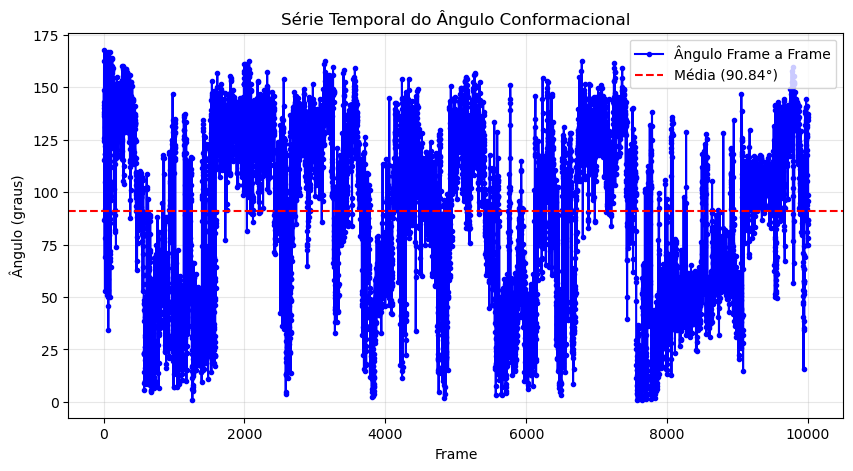

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Substitua pelo nome do arquivo gerado pelo seu script
arquivo_dados = "traj_w_nj_m_c_rtt_angles_FRAMES.dat"

frames = []
angulos = []


with open(arquivo_dados, 'r') as f:
    linhas = f.readlines()[1:] 
    for linha in linhas:
        colunas = linha.split()
        if len(colunas) >= 2:
            frames.append(float(colunas[0]))
            angulos.append(float(colunas[1])) 


media = np.mean(angulos)

plt.figure(figsize=(10, 5))
plt.plot(frames, angulos, marker='o', linestyle='-', color='b', markersize=3, label='Ângulo Frame a Frame')
plt.axhline(y=media, color='r', linestyle='--', label=f'Média ({media:.2f}°)')

plt.title('Série Temporal do Ângulo Conformacional')
plt.xlabel('Frame')
plt.ylabel('Ângulo (graus)')
plt.legend()
plt.grid(True, alpha=0.3)


plt.savefig("grafico_angulos.png", dpi=300, bbox_inches='tight')
plt.show()

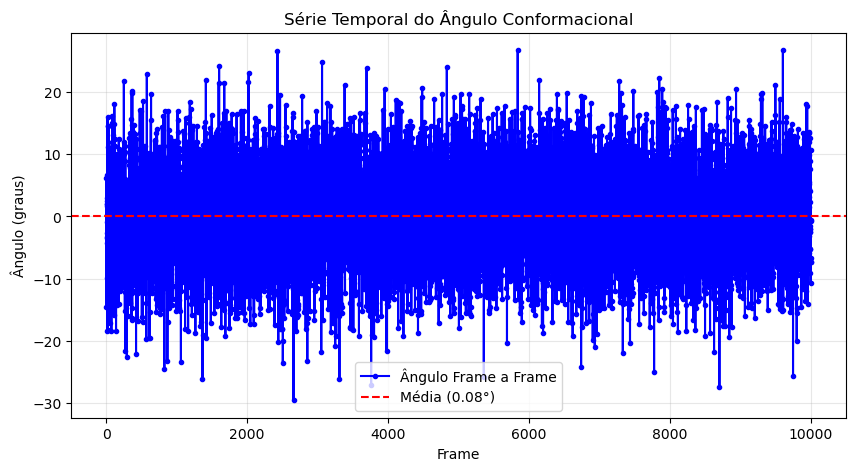

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Substitua pelo nome do arquivo gerado pelo seu script
arquivo_dados = "traj_w_nj_m_c_rtt_dihedrals_FRAMES.dat"

frames = []
angulos = []


with open(arquivo_dados, 'r') as f:
    linhas = f.readlines()[1:] 
    for linha in linhas:
        colunas = linha.split()
        if len(colunas) >= 2:
            frames.append(float(colunas[0]))
            angulos.append(float(colunas[1])) 


media = np.mean(angulos)

plt.figure(figsize=(10, 5))
plt.plot(frames, angulos, marker='o', linestyle='-', color='b', markersize=3, label='Ângulo Frame a Frame')
plt.axhline(y=media, color='r', linestyle='--', label=f'Média ({media:.2f}°)')

plt.title('Série Temporal do Ângulo Conformacional')
plt.xlabel('Frame')
plt.ylabel('Ângulo (graus)')
plt.legend()
plt.grid(True, alpha=0.3)


plt.savefig("grafico_dihedrals.png", dpi=300, bbox_inches='tight')
plt.show()